In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from lifelines import KaplanMeierFitter
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
# To complete this project the user must load CDC linked birth/infant death data, 
# e.g., the 2024 period / 2023 cohort. Download and unzip this file into this 
# notebook's folder from the following site:
# https://ftp.cdc.gov/pub/Health_Statistics/NCHS/Datasets/DVS/period-cohort-linked/2024PE2023CO.zip
# For the column definitions, see the "User Guide to the 2024 Period/2023 Cohort Linked
# Birth/Infant Death Public Use File" located in the CDC Vital Statistics Online portal:
# https://ftp.cdc.gov/pub/Health_Statistics/NCHS/Dataset_Documentation/DVS/period-cohort-linked/24PE23CO_linkedUG.pdf

# The file was downloaded and unzipped to this location local to this notebook's directory.
# We only use the VS2023LINK.Public.USDENPUB_add_Seq_for2023Cohort_r2026_01_14 document in our analysis
DENOM_PATH = "2024PE2023CO/VS2023LINK.Public.USDENPUB_add_Seq_for2023Cohort_r2026_01_14"

In [3]:
# We survey the column positions from the user guide pdf in the following 
# manner(1-indexed, inclusive): (start, end). These are based on the user 
# guide since each row represents a babby record and we use the record 
# layout table in the user guide PDF, e.g., the "2024 Period/2023 Cohort 
# Linked Public Use File Layout" section

# Read below in the comments to see what each parameter measures
# We don't know which factors are significant a priori so we include many now

FIELDS = {
    "restatus": (104, 104), # residency status, 4 = foreign resident (exclude foreign residents)
    "oegest_r3": (503, 503), # preterm flag, 1 = under 37 weeks (preterm)
    "mager": (75, 76), # mother's age in years
    "mracehisp": (117, 117), # mother's race/Hispanic origin
    "meduc": (124, 124), # education, 9 = unknown
    "precare5": (227, 227), # month prenatal care began, 5 = unknown
    "cig_rec": (269, 269), # smoked during pregnancy
    "bmi": (283, 286), # pre-pregnancy BMI, 99.9 = unknown
    "rf_pdiab": (313, 313), # pre-pregnancy diabetes
    "rf_gdiab": (314, 314), # gestational diabetes
    "rf_phype": (315, 315), # pre-pregnancy hypertension
    "rf_ghype": (316, 316), # gestational hypertension
    "rf_ehype": (317, 317), # hypertension eclampsia
    "rf_ppb": (318, 318), # previous preterm birth
    "rf_inft": (325, 325), # infertility treatment
    "ld_ster": (385, 385), # steroids given before delivery
    "ld_chor": (387, 387), # chorioamnionitis (a type of infection)
    "dmeth_rec": (408, 408), # delivery method, 1 = vaginal, 2 = C-section, 9 = unknown
    "pay_rec": (436, 436), # payment method, 1 = medicaid, 2 = private, 3 = self, 4 = other, 9 = unknown
    "apgar5": (444, 445), # 5-minute APGAR, 99 = unknown
    "dplural": (454, 454), # number of babies, 1 = single, 2 = twins, 3 = triplets, 4 = quadruplets+
    "sex": (475, 475), # M/F (one baby per row in the data, so no issues here)
    "oegest": (499, 500), # gestational age in weeks, 99 = unknown
    "brthwgt": (512, 515), # birth weight in grams, 9999 = unknown
    "bwtimp": (516, 516), # 1 = birth weight was imputed
    "ab_aven6": (518, 518), # assisted ventilation > 6 hours
    "ab_nicu": (519, 519), # admitted to NICU
    "ab_surf": (520, 520), # surfactant given
    "ilive": (568, 568), # infant living at time of report
    "co_seqnum": (365, 371), # only filled in if the infant died
    "co_yod": (372, 375), # year of death; with co_seqnum, links to the death files
    "no_congen": (561, 561), # 1 = no birth defects, 0 = at least one, 9 = not reported
    "f_rf_inft": (328, 328), # 1 = state reports infertility treatment, 0 = not reported
}

In [4]:

# Read 500,000 rows at a time due to different ram/memory capabilities of 
# those using this file and keep only preterm births to U.S. residents, 
# so the large file never has to fit in memory all at once
# First we set up the reader using read_fwf (nothing is read yet)
# Then we read in the data

colspecs = [(start - 1, end) for start, end in FIELDS.values()]
chunks = pd.read_fwf(DENOM_PATH, colspecs=colspecs, names=list(FIELDS),
                     dtype=str, encoding="latin-1", chunksize=500000)

kept_pieces = []                         

# here we keep rows in the chunks only when the mother is a US resident and 
# and the baby was born prematurely 

for c in chunks:
    is_preterm = c["oegest_r3"] == "1"
    is_us_resident = c["restatus"] != "4"
    keep = is_preterm & is_us_resident
    kept_pieces.append(c[keep])

df = pd.concat(kept_pieces)   
print("Preterm births loaded from CDC data:", len(df))

Preterm births loaded from CDC data: 373902


In [5]:
# Since we want to track the deaths for these births one year out, we need
# the death files from the CDC data, including deaths in 2023 and deaths in 2024.
# That's because babies born in late 2023 could die in 2024, so both are needed.
# These files are found in the zip file that the user should have previously downloaded.

NUM_FILES = [
    "2024PE2023CO/VS2023LINK.Public.USNUMPUB_R2024_11_27",
    "2024PE2023CO/VS2024LINK.Public.USNUMPUB_R2026_01_14",
]

# Positions from the User Guide's numerator layout (similar to how we built the FIELDS
# dictionary.

DEATH_FIELDS = {
    "dob_yy": (9, 12), # birth year
    "restatus": (104, 104), # residency status, 4 = foreign resident (exclude foreign residents)
    "co_seqnum": (365, 371), # cohort sequence number to link birth/death record
    "co_yod": (372, 375), # year of death
    "aged": (1356, 1358), # age at death in days (0-364)
    "ucodr130": (1373, 1375), # cause of death, 130-category infant recode
}

death_colspecs = [(start - 1, end) for start, end in DEATH_FIELDS.values()]

# No chunking used since the files are small
deaths = pd.concat(
    pd.read_fwf(path, colspecs=death_colspecs, names=list(DEATH_FIELDS),
                dtype=str, encoding="latin-1")
    for path in NUM_FILES
)

# Then we keep only babies born in 2023 to U.S. residents (matching our births)
# We also drop those rows that don't fit the criteria
deaths = deaths[(deaths["dob_yy"] == "2023") & (deaths["restatus"] != "4")]
for col in ["co_seqnum", "co_yod", "aged"]:
    deaths[col] = pd.to_numeric(deaths[col], errors="coerce")
deaths = deaths.dropna(subset=["co_seqnum", "co_yod"])

print("Number of infant deaths among 2023 births: ", len(deaths))

Number of infant deaths among 2023 births:  19743


In [6]:
# Here we do additional data cleaning, e.g., convert text to numbers,
# turn unknown codes and blanks into NaN, etc., for our k-means analysis
# and to avoid errors.

unknown_codes = {
    "bmi": 99.9, 
    "apgar5": 99, 
    "oegest": 99,
    "brthwgt": 9999,
    "meduc": 9,
    "precare5": 5}

# Note that mager (mother's age) and dplural (number of babies born)
# has no default values but are in fact numerical values

num_cols = ["mager", "dplural"] + list(unknown_codes)

df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
for col, code in unknown_codes.items():
    df.loc[df[col] == code, col] = np.nan
    
# We similarly organize the Yes/No fields: Y := 1, N := 0, U (unknown) := NaN 
# using a lambda function 
yn_cols = ["cig_rec", "rf_pdiab", "rf_gdiab", "rf_phype", "rf_ghype",
           "rf_ehype", "rf_ppb", "rf_inft", "ld_ster", "ld_chor",
           "ab_aven6", "ab_nicu", "ab_surf", "ilive"]
df[yn_cols] = df[yn_cols].apply(lambda s: s.map({"Y": 1, "N": 0}))

# The sequence number is only present if the infant died
df["infant_died"] = df["co_seqnum"].notna().astype(int)

# Here we drop rows where NCHS had to guess the birth weight of the baby
df = df[df["bwtimp"] != "1"]

# Birth defects: flip "no anomalies" into "any anomaly" so 1 := has a defect,
# 0 := has no defect, and then anything else, e.g., 9 (not reported) becomes NaN.
df["any_anomaly"] = df["no_congen"].map({"0": 1, "1": 0})

In [7]:
# Link each birth to its death record, assuming the child died, to get age at death.
# Note that not all children died. Then convert the link keys to numbers so they 
# match the death files.

for col in ["co_seqnum", "co_yod"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Here we keep every birth and then add age at death if a death record matches
df = df.merge(deaths[["co_seqnum", "co_yod", "aged", "ucodr130"]],
              on=["co_seqnum", "co_yod"], how="left")

# For our survival analysis, we need two columns:
# the "days" column, e.g., how long each baby was followed (age at death, or 365 if they survived)
# the "event" column, e.g., 1 if the baby died, 0 if the baby survived the first year
df["days"] = df["aged"].fillna(365)
df["event"] = df["infant_died"]

# Check: matched deaths should equal (or nearly equal) the infant_died count
print("Number of deaths flagged in births file: ", df['infant_died'].sum())
print("Number of deaths with age at death: ", df['aged'].notna().sum())

Number of deaths flagged in births file:  11993
Number of deaths with age at death:  11993


In [8]:
# Here we poerform a sanity check. That is, death rates should drop sharply 
# with gestational age. As an additional internal check, recall that CDC 
# reports roughly 357 deaths per 1,000 births under 28 weeks)

print("Infant deaths: ", df['infant_died'].sum())
df["gest_group"] = pd.cut(df["oegest"], bins=[0, 27, 31, 33, 36],
                          labels=["<28 wks", "28-31", "32-33", "34-36"])
print((df.groupby("gest_group", observed=True)["infant_died"].mean() * 1000).round(1))

Infant deaths:  11993
gest_group
<28 wks    338.0
28-31       42.7
32-33       20.2
34-36        8.1
Name: infant_died, dtype: float64


In [9]:
# Here we show the percent of missing values in each column, printing the highest first.
# We do this because columns with lots of missing data are poor choices for clustering.
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing)

bwtimp         100.0
co_seqnum       96.8
aged            96.8
ucodr130        96.8
co_yod          96.8
bmi              3.2
precare5         3.1
meduc            2.1
apgar5           0.7
cig_rec          0.6
ilive            0.5
any_anomaly      0.4
rf_inft          0.2
rf_ghype         0.2
rf_ppb           0.2
rf_ehype         0.2
rf_phype         0.2
rf_gdiab         0.2
rf_pdiab         0.2
ab_nicu          0.1
ab_surf          0.1
ab_aven6         0.1
ld_ster          0.1
ld_chor          0.1
no_congen        0.0
f_rf_inft        0.0
infant_died      0.0
days             0.0
event            0.0
restatus         0.0
dplural          0.0
brthwgt          0.0
oegest           0.0
sex              0.0
oegest_r3        0.0
pay_rec          0.0
dmeth_rec        0.0
mracehisp        0.0
mager            0.0
gest_group       0.0
dtype: float64


In [10]:
# For our analysis we keep births at 22+ weeks: earlier births are generally not viable,
# so their outcomes reflect viability rather than risk-factor patterns. We also drop birth 
# weights above 5,000 g, since babies are rarely that big and it makes sure the data makes 
# sense (a value of > 11 lbs is likely an error).
before = len(df)
df = df[(df["oegest"] >= 22) & (df["brthwgt"] <= 5000)]
print("Removed", before - len(df)," records; ", len(df)," records remain")

Removed 2695  records;  370003  records remain


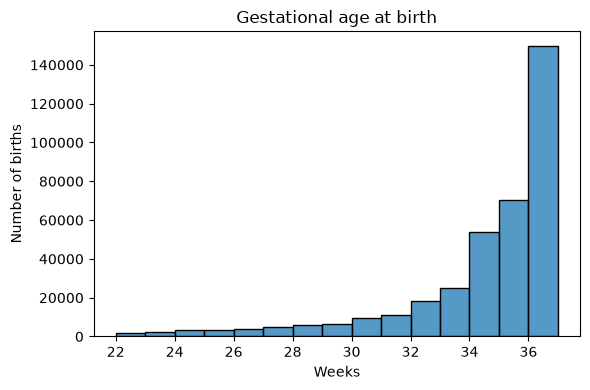

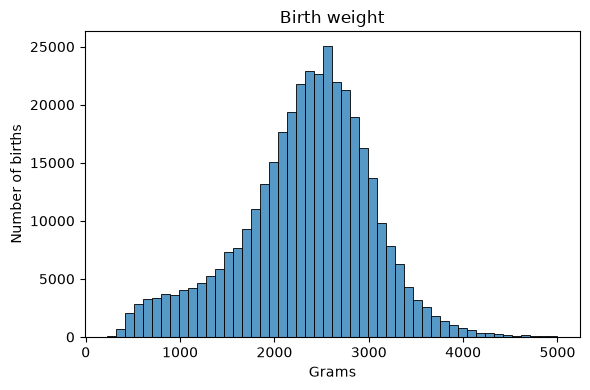

In [11]:
# Here we show the distributions of gestational age and birth weight among preterm births

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(df["oegest"], bins=range(22, 38), ax=ax)
ax.set(title="Gestational age at birth", xlabel="Weeks", ylabel="Number of births")
plt.tight_layout()
fig.savefig("gestational_age.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(df["brthwgt"], bins=50, ax=ax)
ax.set(title="Birth weight", xlabel="Grams", ylabel="Number of births")
plt.tight_layout()
fig.savefig("birth_weight.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# Convert plurality (number of babies delivered) to yes/no, e.g.,
# 1 = twin or more, 0 = single birth
df["multiple_birth"] = (df["dplural"] > 1).astype(int)

# Features known at or before birth that are used for clustering analysis
FEATURES = [
    "oegest", "brthwgt", # how early and how small the baby is
    "multiple_birth", # whether the mother gave birth to twins or more
    "mager", # the mother's age
    "rf_pdiab", "rf_gdiab", # whether the mother had diabetes (either before or during pregnancy)
    "rf_phype", "rf_ghype", "rf_ehype", # whether the mother had high blood pressure conditions
    "rf_ppb", # whether the mother previous suffered a preterm birth
    "rf_inft", # whether the mother underwent infertility treatment
    "ld_chor", # whether the mother had a chorioamnionitis infection
    "cig_rec", # smoking during pregnancy
]

# We record what happened after birth, e.g., which is used only to compare clusters afterward
OUTCOMES = ["infant_died", "ab_nicu", "ab_aven6", "ab_surf"]

# We want to keep only births with no missing values in the features
model_df = df.dropna(subset=FEATURES).copy()
print("Births with complete feature data: ", len(model_df), "of", len(df))
print("Percent complete: ", round(100 * len(model_df) / len(df), 1))

Births with complete feature data:  367081 of 370003
Percent complete:  99.2


In [13]:
# for the ML side of the project, we know that k-means uses distances, 
# so features must be on comparable scales. Without this transformation, 
# a feature like birth weight, which can large, would dominate binry y/n, e.g., 0 or 1 features. 

scaler = StandardScaler()
X = scaler.fit_transform(model_df[FEATURES])
print("Feature matrix shape:", X.shape)

Feature matrix shape: (367081, 13)


k = 2 , inertia: 4321502 , silhouette: 0.222
k = 3 , inertia: 3958275 , silhouette: 0.229
k = 4 , inertia: 3595624 , silhouette: 0.243
k = 5 , inertia: 3282828 , silhouette: 0.242
k = 6 , inertia: 2954646 , silhouette: 0.241
k = 7 , inertia: 2606217 , silhouette: 0.276
k = 8 , inertia: 2386898 , silhouette: 0.272


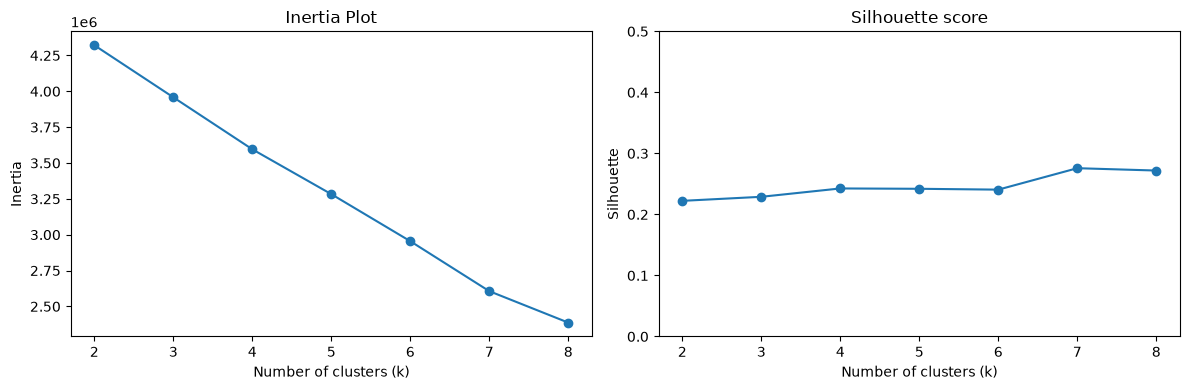

In [14]:
# Try k = 2, 3, ..., 8 and record two measures of cluster quality
# The inertia, e.g., the sum of squared distances from each point to its cluster
# center (lower = tighter). And then the silhouette, or rather how well-separated 
# the clusters are, from -1 to 1 (higher = better). The calculation is averaged 
# over 5 random samples of 10000 births.

ks = range(2, 9)
inertias, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    scores = [silhouette_score(X, km.labels_, sample_size=10000, random_state=seed)
              for seed in range(5)]
    silhouettes.append(np.mean(scores))
    print("k =", k, ", inertia:", round(km.inertia_), ", silhouette:", round(silhouettes[-1], 3))

# Plot both measures and save them
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set(title="Inertia Plot", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(ks, silhouettes, marker="o")
axes[1].set(title="Silhouette score", xlabel="Number of clusters (k)", ylabel="Silhouette")
axes[1].set_ylim(0, 0.5)  
plt.tight_layout()
fig.savefig("inertia_silhouette.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# Here we fit the final k-means model with the chosen number of clusters based on the graph (use 7 in this case)

K = 7
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
model_df["cluster"] = kmeans.labels_
profile = model_df.groupby("cluster")[FEATURES + OUTCOMES].mean()
profile.insert(0, "n_births", model_df["cluster"].value_counts().sort_index())

profile["deaths_per_1000"] = profile["infant_died"] * 1000
profile.round(2).T

cluster,0,1,2,3,4,5,6
n_births,53530.00,4443.00,35784.00,12256.00,14772.00,242929.00,3367.00
oegest,28.89,31.61,34.35,33.97,33.71,35.12,33.58
brthwgt,1244.15,1964.07,2405.69,2651.45,2229.01,2564.00,2175.91
multiple_birth,0.28,0.14,0.14,0.10,0.43,0.17,0.13
mager,29.26,29.49,31.09,31.73,35.32,29.68,29.53
rf_pdiab,0.00,0.04,0.00,1.00,0.00,0.00,0.06
rf_gdiab,0.07,0.11,0.14,0.00,0.17,0.12,0.12
rf_phype,0.08,0.05,0.10,0.28,0.08,0.05,0.09
rf_ghype,0.20,0.14,0.18,0.29,0.27,0.20,0.16
rf_ehype,0.00,0.00,0.00,0.00,0.00,0.00,1.00


Variance explained by 2 components (%):  24.4


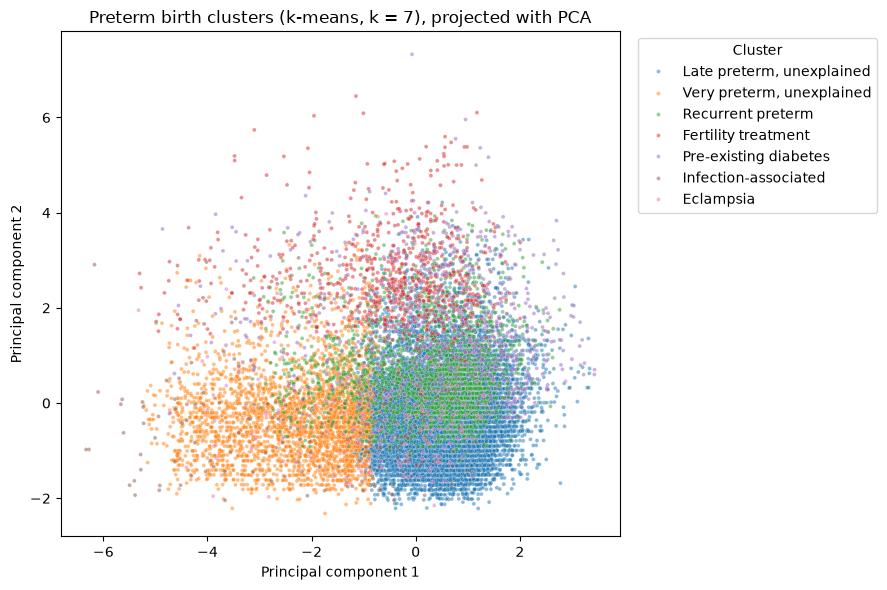

In [16]:
# Here we give the clusters names based on the profile table
cluster_names = {
    0: "Very preterm, unexplained",
    1: "Infection-associated",
    2: "Recurrent preterm",
    3: "Pre-existing diabetes",
    4: "Fertility treatment",
    5: "Late preterm, unexplained",
    6: "Eclampsia",
}
model_df["cluster_name"] = model_df["cluster"].map(cluster_names)

# Here we perform principal component analysis along two dimentions 
# to see the two places where births differ the most
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)
print("Variance explained by 2 components (%): ", round(100 * pca.explained_variance_ratio_.sum(), 1))
# Then we plot a random sample of 20000 births (for readability, 
# we don't use the full set):
rng = np.random.default_rng(42)
idx = rng.choice(len(X_2d), size=20000, replace=False)
sizes = model_df["cluster"].value_counts()
idx = idx[np.argsort(-sizes[model_df["cluster"].values[idx]].values)]

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_2d[idx, 0], y=X_2d[idx, 1],
                hue=model_df["cluster_name"].values[idx],
                s=8, alpha=0.5, palette="tab10")
plt.title("Preterm birth clusters (k-means, k = 7), projected with PCA")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("pca_clusters.png", dpi=300, bbox_inches="tight")
plt.show()


In [17]:
# Here we evaluate how strongly each feature contributes to each principal component.
# Large positive or negative values means that feature drives the axis.
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
loadings.round(2).sort_values("PC1")

,PC1,PC2
multiple_birth,-0.20,0.14
ld_chor,-0.12,-0.02
rf_inft,-0.07,0.44
rf_phype,-0.03,0.44
rf_ehype,-0.02,-0.00
cig_rec,-0.02,0.02
rf_ppb,0.00,0.23
rf_ghype,0.01,-0.03
mager,0.03,0.62
rf_pdiab,0.06,0.25


In [18]:
# Here we look at a second clustering method, e.g., a Gaussian mixture model (GMM) 
# on the same standardized features and number of clusters, to check which k-means
# groups are robust. 

# It's worth adding a small value to each cluster's variance since
# y/n (0 or 1) features can have zero variance within a cluster
gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=3,
                      reg_covar=0.1, random_state=42)
model_df["gmm_cluster"] = gmm.fit_predict(X)
confidence = gmm.predict_proba(X).max(axis=1)
print("Median assignment confidence: ", round(np.median(confidence), 2))

# Then we look at the Adjusted Rand Index (ARI) to see how similarly the two methods 
# group births (1 := identical, 0 := no better than random)
print("Adjusted Rand Index (k-means vs GMM): ",
      round(adjusted_rand_score(model_df["cluster"], model_df["gmm_cluster"]), 2))

# For each K-means cluster (e.g., rows), the percent of its births in each GMM
# cluster (e.g., columns). A row near 100% in one column highly suggests that both methods agree.
pd.crosstab(model_df["cluster_name"], model_df["gmm_cluster"],
            normalize="index").mul(100).round(1)

Median assignment confidence:  1.0
Adjusted Rand Index (k-means vs GMM):  0.18


gmm_cluster,0,1,2,3,4,5,6
cluster_name,,,,,,,
Eclampsia,100.0,0.0,0.0,0.0,0.0,0.0,0.0
Fertility treatment,0.0,0.0,0.0,33.4,49.4,17.2,0.0
Infection-associated,0.0,0.0,0.0,0.0,100.0,0.0,0.0
"Late preterm, unexplained",0.0,13.6,53.2,14.0,0.0,11.9,7.3
Pre-existing diabetes,0.0,28.3,0.0,0.0,3.3,0.0,68.4
Recurrent preterm,0.0,12.4,0.0,10.0,0.0,13.8,63.7
"Very preterm, unexplained",0.0,15.0,43.6,22.9,0.0,6.5,11.9


In [19]:
# Here we try the GMM on continuous features only, since the bell curve
# assumption is reasonable in this setting, e.g., gestational age, birthweight, and
# mother's age.

cont_features = ["oegest", "brthwgt", "mager"]

# Note that the gestational age and the mother's age are recorded in whole numbers, 
# which lets the GMM fit zero-width "spikes" on common values like 36 weeks. We can make
# these "continuous" by adding small random noise (e.g., +/- 0.5) spreads to each value 
# withouth disrupting the validity of the data.

rng_jitter = np.random.default_rng(42)
cont = model_df[cont_features].astype(float).copy()
cont["oegest"] += rng_jitter.uniform(-0.5, 0.5, len(cont))
cont["mager"] += rng_jitter.uniform(-0.5, 0.5, len(cont))
X_cont = StandardScaler().fit_transform(cont)

# Bayesian Information Criterion (BIC) is a score for comparing statistical models fitted
# to the same data. It helps to find the simplest model that explains the data well. In this
# setting, lower is better and we choose the number of components where it is lowest.

for n in range(2, 7):
    g = GaussianMixture(n_components=n, covariance_type="full", random_state=42).fit(X_cont)
    print(n, "components: BIC =", round(g.bic(X_cont))) 


2 components: BIC = 2474544
3 components: BIC = 2465948
4 components: BIC = 2352277
5 components: BIC = 2341771
6 components: BIC = 2343464


In [20]:
# Then we run the final model with 5 components (lowest BIC)
gmm_cont = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
model_df["gmm_cont"] = gmm_cont.fit_predict(X_cont)
cont_confidence = gmm_cont.predict_proba(X_cont).max(axis=1)

# We see that the confidence is now meaningful, e.g, births between groups get lower values
print("Median confidence: ", round(np.median(cont_confidence), 2))
print("Percent of births with < 70% confidence: ", round(100 * (cont_confidence < 0.7).mean(), 1))

# Let's look at the average gestational age, birth weight, mother's age, and death rate per component
summary = model_df.groupby("gmm_cont").agg(
    births=("oegest", "size"),
    gest_age=("oegest", "mean"),
    birth_weight=("brthwgt", "mean"),
    mother_age=("mager", "mean"),
    deaths_per_1000=("infant_died", lambda s: s.mean() * 1000),
)

component_names = {
    4: "Extremely/very preterm",
    0: "Very/moderate preterm",
    3: "Late preterm, smaller",
    1: "Late preterm, larger",
    2: "Near-term",
}

print(summary.rename(index=component_names).loc[list(component_names.values())].round(1))

# Does the GMM rediscover the standard clinical gestational age categories? As we see below, the answer is partly
crosstab_cont = pd.crosstab(model_df["gest_group"], model_df["gmm_cont"].map(component_names),
                            normalize="index").mul(100).round(1)
crosstab_cont[list(component_names.values())]   # order columns from earliest to latest

Median confidence:  0.75
Percent of births with < 70% confidence:  41.5
                        births  gest_age  birth_weight  mother_age  \
gmm_cont                                                             
Extremely/very preterm   39519      27.3        1031.4        29.6   
Very/moderate preterm    41143      31.8        1897.1        31.1   
Late preterm, smaller    94502      34.2        2224.4        28.5   
Late preterm, larger     51916      35.1        2801.8        33.3   
Near-term               140001      36.0        2732.5        29.7   

                        deaths_per_1000  
gmm_cont                                 
Extremely/very preterm            147.9  
Very/moderate preterm              30.6  
Late preterm, smaller              10.6  
Late preterm, larger                9.6  
Near-term                           6.2  


gmm_cont,Extremely/very preterm,Very/moderate preterm,"Late preterm, smaller","Late preterm, larger",Near-term
gest_group,,,,,
<28 wks,98.9,1.1,0.0,0.0,0.0
28-31,61.4,38.6,0.0,0.0,0.0
32-33,0.6,61.0,38.4,0.0,0.0
34-36,0.0,0.9,28.7,19.1,51.4


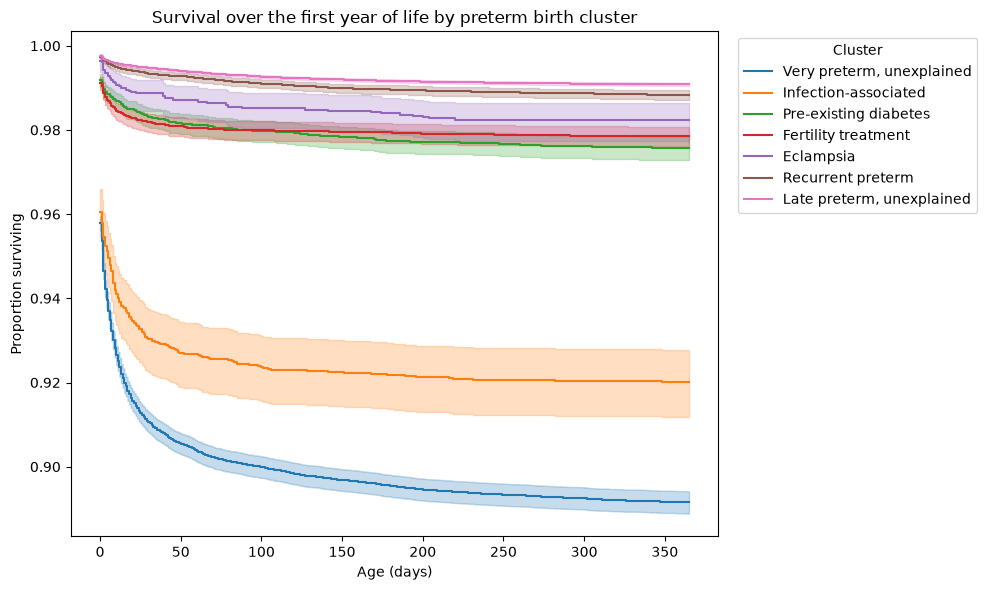

In [21]:
# Now we try to understand survivability of these preterm babies
# We use Kaplan-Meier curves to do so. These curves estimates the share of babies 
# still alive at each day of life. We plot one curve per k-means cluster, 
# ordered from highest to lowest death rate. We exclude any deaths whose death record didn't match

surv_df = model_df[~((model_df["event"] == 1) & model_df["aged"].isna())]

fig, ax = plt.subplots(figsize=(10, 6))
kmf = KaplanMeierFitter()

order = surv_df.groupby("cluster_name")["event"].mean().sort_values(ascending=False).index
for name in order:
    group = surv_df[surv_df["cluster_name"] == name]
    kmf.fit(group["days"], group["event"], label=name)
    kmf.plot_survival_function(ax=ax, ci_show=True)

ax.set(title="Survival over the first year of life by preterm birth cluster",
       xlabel="Age (days)", ylabel="Proportion surviving")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig("survival.png", dpi=300, bbox_inches="tight")
plt.show()

# Note that the y-axis starts at > ~0.87-0.88

In [22]:
# In the below table we can see among babies who died, what 
# share died in the first day, week, and month

died = surv_df[surv_df["event"] == 1]
timing = died.groupby("cluster_name")["days"].agg(
    deaths="size",
    first_day=lambda d: (d == 0).mean(),
    first_week=lambda d: (d < 7).mean(),
    first_month=lambda d: (d < 28).mean(),
)
timing[["first_day", "first_week", "first_month"]] *= 100   # show as percentages
timing.round(1).sort_values("deaths", ascending=False)

,deaths,first_day,first_week,first_month
cluster_name,,,,
"Very preterm, unexplained",5806,38.9,60.1,81.3
"Late preterm, unexplained",2230,27.4,41.5,55.8
Recurrent preterm,417,22.3,38.1,54.2
Infection-associated,355,49.3,65.1,85.6
Fertility treatment,316,41.5,63.6,83.5
Pre-existing diabetes,297,33.3,48.8,68.0
Eclampsia,59,20.3,44.1,64.4


In [23]:
# The we look at the share of births with a birth defect in each cluster, and death rates
# and death rates with and without babies who had a defect
anomaly_check = model_df.groupby("cluster_name").agg(
    births=("any_anomaly", "size"),
    pct_with_defect=("any_anomaly", lambda s: s.mean() * 100),
    deaths_per_1000_all=("infant_died", lambda s: s.mean() * 1000),
)
no_defect = model_df[model_df["any_anomaly"] == 0]
anomaly_check["deaths_per_1000_no_defect"] = (
    no_defect.groupby("cluster_name")["infant_died"].mean() * 1000
)
anomaly_check.round(1).sort_values("deaths_per_1000_all", ascending=False)

,births,pct_with_defect,deaths_per_1000_all,deaths_per_1000_no_defect
cluster_name,,,,
"Very preterm, unexplained",53530,1.2,108.5,104.6
Infection-associated,4443,1.0,79.9,76.9
Pre-existing diabetes,12256,1.3,24.2,21.8
Fertility treatment,14772,0.7,21.4,20.2
Eclampsia,3367,0.7,17.5,16.5
Recurrent preterm,35784,0.8,11.7,10.1
"Late preterm, unexplained",242929,0.8,9.2,7.9


In [24]:
# Let's group the cause of deaths, e.g., map them from the larger 130+ codes to 
# about 8 (we could have done a different set of categorizations, but this is suitable)

def cause_group(c):
    if 71 <= c <= 85:
        return "Pregnancy / delivery complications"
    elif 88 <= c <= 90:
        return "Short gestation / low birth weight"
    elif 105 <= c <= 108:
        return "Newborn infections"
    elif c in (70, 86, 87) or 91 <= c <= 104 or 109 <= c <= 117:
        return "Other newborn conditions"     
    elif 118 <= c <= 133:
        return "Birth defects"
    elif c in (135, 136, 146):
        return "Sudden unexpected infant death"
    elif 138 <= c <= 145 or 147 <= c <= 158:
        return "Injury"                       
    else:
        return "Other"

died = model_df[model_df["infant_died"] == 1].copy()

# Let's convert the cause codes from text to whole numbers, then group them
codes = pd.to_numeric(died["ucodr130"], errors="coerce").dropna().astype(int)
died["cause"] = codes.map(cause_group)

# Then for each cluster, what percent of deaths fall in each cause group? See the table below for the result
pd.crosstab(died["cluster_name"], died["cause"], normalize="index").mul(100).round(1).T

cluster_name,Eclampsia,Fertility treatment,Infection-associated,"Late preterm, unexplained",Pre-existing diabetes,Recurrent preterm,"Very preterm, unexplained"
cause,,,,,,,
Birth defects,11.9,14.2,8.2,43.5,23.6,31.7,13.7
Injury,1.7,0.0,0.0,3.1,1.0,3.6,0.6
Newborn infections,6.8,6.3,14.1,1.5,3.4,2.6,9.1
Other,10.2,8.2,8.5,12.9,12.8,13.9,9.5
Other newborn conditions,37.3,43.0,31.3,13.1,34.3,18.5,39.6
Pregnancy / delivery complications,5.1,9.5,19.2,3.7,7.1,6.7,9.6
Short gestation / low birth weight,13.6,17.1,15.5,0.5,8.8,1.0,15.3
Sudden unexpected infant death,13.6,1.6,3.4,21.6,9.1,22.1,2.5
